# SMAI Assignment 4 - Question 1

#### Imports

In [1]:
%pip install torchmetrics
%pip install wandb

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
import torch
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import datasets, transforms
import numpy as np
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchmetrics.classification import Accuracy
from torchmetrics import MeanAbsoluteError, MeanSquaredError
import wandb
import time
from torch.nn.utils import clip_grad_norm_
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

In [3]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cuda


## Data Loading and Preprocessing

### Dataset Class Definition

In [4]:
class FashionMNISTDataset(Dataset):
    """
    Custom Dataset wrapper for Fashion-MNIST to return image, class label, and ink target.

    Args:
        dataset (Dataset): The original torchvision Fashion-MNIST dataset.
        transform (callable, optional): A function/transform to apply to the image.
    """
    def __init__(self, dataset, transform=None):
        self.dataset = dataset
        self.transform = transform
        # This simple transform is only to convert PIL to Tensor to calculate ink
        self.to_tensor = transforms.ToTensor()

    def __len__(self):
        """Returns the size of the dataset."""
        return len(self.dataset)

    def __getitem__(self, idx):
        """
        Fetches the item at a given index.

        Returns:
            tuple: (image, class_label, ink_target) where
                   - image is the transformed image tensor.
                   - class_label is the integer label.
                   - ink_target is the normalized average pixel intensity.
        """
        # Get the raw image and its label
        image, label = self.dataset[idx]

        # Convert image to tensor to calculate ink before normalization
        image_tensor = self.to_tensor(image)

        # Calculate ink_target: the average pixel value (normalized intensity)
        # done on the 0-1 scaled tensor before other normalizations.
        ink_target = torch.mean(image_tensor).item() # compute after transform (light augmentation)??

        # Apply the full augmentation/normalization pipeline if it exists
        if self.transform:
            image = self.transform(image)
        else:
            # If no other transform, use the tensor we already made
            image = image_tensor

        return image, label, ink_target

### Dataset Loading and Preprocessing Function

In [5]:
# Mean and std dev for Fashion-MNIST from online resources
mean = (0.2860,)
std = (0.3530,)

def load_fashion_data(batch_size=64):
    """
    Loads and preprocesses the Fashion-MNIST dataset.

    This function handles dataset downloading, splitting, creating custom datasets, and setting up DataLoaders.

    Args:
        batch_size (int): The number of samples per batch.

    Returns:
        tuple: (train_loader, val_loader, test_loader)
    """

    # Transformations for the training set with light augmentations
    train_transform = transforms.Compose([
        transforms.RandomRotation(10),       # Small rotation
        transforms.RandomCrop(28, padding=4),# Random crop
        transforms.ToTensor(),               # Convert PIL Image to tensor (scales to [0, 1])
        transforms.Normalize(mean, std)      # Normalize with mean and std
    ])

    # Transformations for the validation and test sets (no augmentation)
    test_val_transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(mean, std)
    ])

    # load datasets
    full_train_dataset_raw = datasets.FashionMNIST(
        root='./data', train=True, download=True
    )
    test_dataset_raw = datasets.FashionMNIST(
        root='./data', train=False, download=True
    )

    # split train into train and validation
    train_size = int(0.9 * len(full_train_dataset_raw))
    val_size = len(full_train_dataset_raw) - train_size
    train_dataset_raw, val_dataset_raw = random_split(
        full_train_dataset_raw, [train_size, val_size]
    )
    print(f" - Training set size: {len(train_dataset_raw)}")
    print(f" - Validation set size: {len(val_dataset_raw)}")
    print(f" - Test set size: {len(test_dataset_raw)}")

    # wrap dataset with class
    train_dataset = FashionMNISTDataset(train_dataset_raw, transform=train_transform)
    val_dataset = FashionMNISTDataset(val_dataset_raw, transform=test_val_transform)
    test_dataset = FashionMNISTDataset(test_dataset_raw, transform=test_val_transform)

    # dataloaders
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

    return train_loader, val_loader, test_loader

### Example

In [6]:
train_loader, val_loader, test_loader = load_fashion_data(batch_size=32)

# Fetch one batch to see the output
images, labels, inks = next(iter(train_loader))

print(f"\n--- Batch Shape ---")
print(f"Images batch shape: {images.shape}")
print(f"Labels batch shape: {labels.shape}")
print(f"Inks batch shape: {inks.shape}")

print(f"\n--- Sample Data ---")
print(f"Sample label: {labels[0].item()}")
print(f"Sample ink target: {inks[0].item():.4f}")

 - Training set size: 54000
 - Validation set size: 6000
 - Test set size: 10000

--- Batch Shape ---
Images batch shape: torch.Size([32, 1, 28, 28])
Labels batch shape: torch.Size([32])
Inks batch shape: torch.Size([32])

--- Sample Data ---
Sample label: 7
Sample ink target: 0.1394


Plotting sample images...
  Images batch shape: torch.Size([32, 1, 28, 28])
  Mean for un-normalization: 0.2860
  Std for un-normalization: 0.3530


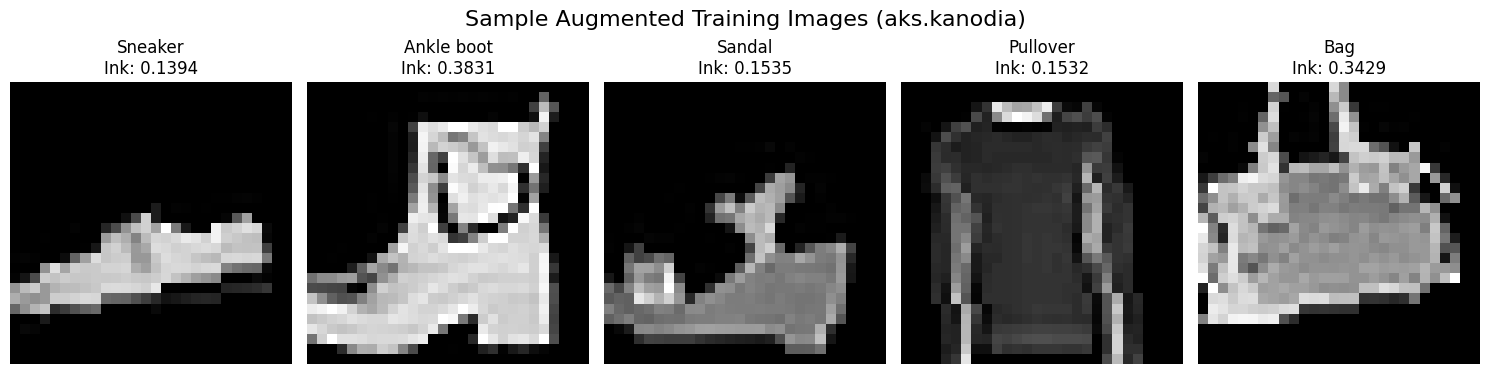

In [7]:
# from assignment
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

fig, axes = plt.subplots(1, 5, figsize=(15, 4))
axes = axes.ravel() # Flatten the 1x5 grid

print(f"Plotting sample images...")
print(f"  Images batch shape: {images.shape}")
print(f"  Mean for un-normalization: {mean[0]:.4f}")
print(f"  Std for un-normalization: {std[0]:.4f}")

for i in range(5):
    # Get the image, label, and ink
    image = images[i]
    label = labels[i].item()
    ink = inks[i].item()
    
    # Un-normalize the image
    # We use std[0] and mean[0] because they are tuples like (0.2860,)
    img_unnormalized = image.squeeze() * std[0] + mean[0]
    
    # Plot the image
    axes[i].imshow(img_unnormalized, cmap='gray')
    axes[i].set_title(f"{class_names[label]}\nInk: {ink:.4f}")
    axes[i].axis('off') # Hide axes

# Add a main title with your username
plt.suptitle("Sample Augmented Training Images (aks.kanodia)", fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout
plt.show()

## Model Implementation

### Class Definition

In [8]:
class MultiTaskCNN(nn.Module):
    """
    A Multi-Task CNN for Fashion-MNIST classification and ink regression.

    The architecture consists of a shared convolutional backbone and two separate heads for classification and regression.
    """
    def __init__(self, dropout_rate=0.25):
        """
        Initializes the model layers.

        Args:
            dropout_rate (float): The dropout probability to use.
        """
        super(MultiTaskCNN, self).__init__()

        # Shared backbone

        # Block 1
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2) # Output: 14x14

        # Block 2
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2) # Output: 7x7

        # Block 3
        self.conv3 = nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2) # Output: 3x3

        # Separate Heads

        # We need to calculate the flattened size after the backbone
        # After 3 pooling layers, 28x28 -> 14x14 -> 7x7 -> 3x3
        # The number of channels is 128 from conv3
        self.flatten_features = 128 * 3 * 3

        self.dropout = nn.Dropout(p=dropout_rate)

        # Classification head: outputs [B, 10]
        self.classification_head = nn.Linear(self.flatten_features, 10)

        # Regression head: outputs [B, 1]
        self.regression_head = nn.Linear(self.flatten_features, 1)

    def forward(self, x, return_features=True):
        """
        Defines the forward pass of the model.

        Args:
            x (torch.Tensor): The input batch of images, shape [B, 1, 28, 28].

        Returns:
            tuple: (class_logits, ink_prediction)
                   - class_logits (torch.Tensor): Shape [B, 10]
                   - ink_prediction (torch.Tensor): Shape [B, 1]
        """
        # Block 1
        x = self.conv1(x)
        x = self.bn1(x)
        x = F.relu(x)
        x_block1 = self.pool1(x) # Shape: [B, 32, 14, 14]

        # Block 2
        x = self.conv2(x_block1)
        x = self.bn2(x)
        x = F.relu(x)
        x_block2 = self.pool2(x) # Shape: [B, 64, 7, 7]

        # Block 3
        x = self.conv3(x_block2)
        x = self.bn3(x)
        x = F.relu(x)
        x_block3 = self.pool3(x) # Shape: [B, 128, 3, 3]

        # flatten
        x_flat = x_block3.view(-1, self.flatten_features)
        x_flat = self.dropout(x_flat)

        # Pass through separate heads
        class_logits = self.classification_head(x_flat)
        ink_prediction = self.regression_head(x_flat)

        # feature maps as a dictionary
        feature_maps = {
            'block1': x_block1,
            'block2': x_block2,
            'block3': x_block3
        }
        
        if return_features:
            return class_logits, ink_prediction, feature_maps
        return class_logits, ink_prediction

### Example Usage

In [9]:
model = MultiTaskCNN(dropout_rate=0.5)
print(model)

# Create a dummy batch of 4 images
sample_batch = torch.randn(4, 1, 28, 28)

# Perform a forward pass
logits, inks, fmaps = model(sample_batch)

print(f"Classification logits shape: {logits.shape}")
print(f"Regression prediction shape: {inks.shape}")
print(f"Feature Maps:")
for name, fmap in fmaps.items():
    print(f"{name} shape: {fmap.shape}")

MultiTaskCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.5, inplace=False)
  (classification_head): Linear(in_features=1152, out_features=10, bias=True)
  (regression_head): Linear(in_features=1152, out_features=1, bias=True)
)
Classification logits shape: torc

### Train Methods (Total Loss is implemented directly within training functions)

In [10]:
def train_epoch(model, loader, optimizer, crit_class, crit_reg, lambda1, lambda2, device):
    """Handles the training logic for a single epoch."""
    model.train()
    running_loss, running_ce, running_mse = 0.0, 0.0, 0.0

    for images, labels, inks in loader:
        images, labels = images.to(device), labels.to(device)
        inks = inks.to(device).float().view(-1, 1) # Ensure correct shape and type

        optimizer.zero_grad()

        # Forward pass
        class_logits, ink_preds = model(images, return_features=False)

        # Calculate individual losses
        loss_ce = crit_class(class_logits, labels)
        loss_mse = crit_reg(ink_preds, inks)

        # Calculate joint loss
        total_loss = (lambda1 * loss_ce) + (lambda2 * loss_mse)

        # Backward pass and optimization
        total_loss.backward()
        clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        running_loss += total_loss.item()
        running_ce += loss_ce.item()
        running_mse += loss_mse.item()

    avg_loss = running_loss / len(loader)
    avg_ce = running_ce / len(loader)
    avg_mse = running_mse / len(loader)

    return avg_loss, avg_ce, avg_mse

def evaluate(model, loader, crit_class, crit_reg, lambda1, lambda2, device):
    """Handles the evaluation logic for validation or test sets."""
    model.eval()
    running_loss, running_ce, running_mse = 0.0, 0.0, 0.0

    # Initialize metrics from torchmetrics
    accuracy = Accuracy(task="multiclass", num_classes=10).to(device)
    mae = MeanAbsoluteError().to(device)
    rmse = MeanSquaredError(squared=False).to(device)

    all_preds_list = []
    all_labels_list = []

    with torch.no_grad():
        for images, labels, inks in loader:
            images, labels = images.to(device), labels.to(device)
            inks = inks.to(device).float().view(-1, 1)

            # Forward pass
            class_logits, ink_preds = model(images, return_features=False)

            # Calculate losses
            loss_ce = crit_class(class_logits, labels)
            loss_mse = crit_reg(ink_preds, inks)
            total_loss = (lambda1 * loss_ce) + (lambda2 * loss_mse)

            running_loss += total_loss.item()
            running_ce += loss_ce.item()
            running_mse += loss_mse.item()

            # Update metrics
            accuracy.update(class_logits, labels)
            mae.update(ink_preds, inks)
            rmse.update(ink_preds, inks)

            all_preds_list.append(torch.argmax(class_logits, dim=1).cpu())
            all_labels_list.append(labels.cpu())

    # Compute final metrics
    avg_loss = running_loss / len(loader)
    avg_ce = running_ce / len(loader)
    avg_mse = running_mse / len(loader)

    all_preds = torch.cat(all_preds_list)
    all_labels = torch.cat(all_labels_list)

    final_acc = accuracy.compute()
    final_mae = mae.compute()
    final_rmse = rmse.compute()

    return avg_loss, avg_ce, avg_mse, final_acc, final_mae, final_rmse, all_preds, all_labels


In [11]:
def run_training_pipeline(model, config, train_loader, val_loader, test_loader, device):
    """
    Main function to run the complete training and evaluation pipeline.
    """
    
    criterion_class = nn.CrossEntropyLoss()
    criterion_reg = nn.MSELoss()

    if config.optimizer == 'adam':
        optimizer = optim.Adam(model.parameters(), lr=config.learning_rate)
    elif config.optimizer == 'adamw':
        optimizer = optim.AdamW(model.parameters(), lr=config.learning_rate)
    else:
        optimizer = optim.SGD(model.parameters(), lr=config.learning_rate, momentum=0.9)

    # Watch the model gradients and parameters with wandb
    wandb.watch(model, log='all', log_freq=100)

    print("--- Starting training loop ---")
    best_val_loss = float('inf')

    for epoch in range(config.epochs):
        start_time = time.time()

        # Train for one epoch
        train_loss, train_ce, train_mse = train_epoch(
            model, train_loader, optimizer, criterion_class, criterion_reg,
            config.lambda1, config.lambda2, device
        )

        # Evaluate on the validation set
        val_loss, val_ce, val_mse, val_acc, val_mae, val_rmse, _, _ = evaluate(
            model, val_loader, criterion_class, criterion_reg,
            config.lambda1, config.lambda2, device
        )

        end_time = time.time()
        epoch_duration = end_time - start_time

        print(
            f"Epoch {epoch+1}/{config.epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.4f} | "
            f"Duration: {epoch_duration:.2f}s"
        )

        # Log metrics to wandb
        wandb.log({
            "epoch": epoch + 1,
            "train_loss_total": train_loss, "train_loss_ce": train_ce, "train_loss_mse": train_mse,
            "val_loss_total": val_loss, "val_loss_ce": val_ce, "val_loss_mse": val_mse,
            "val_accuracy": val_acc, "val_mae": val_mae, "val_rmse": val_rmse
        })

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), "best_model.pth")
            wandb.save("best_model.pth")

    print("\n--- Final Evaluation on Test Set ---")
    model.load_state_dict(torch.load("best_model.pth"))

    test_loss, test_ce, test_mse, test_acc, test_mae, test_rmse, all_preds, all_labels = evaluate(
        model, test_loader, criterion_class, criterion_reg,
        config.lambda1, config.lambda2, device
    )

    print(f"Test Accuracy: {test_acc:.4f}, Test MAE: {test_mae:.4f}, Test RMSE: {test_rmse:.4f}")

    wandb.log({
        "test_accuracy": test_acc, "test_mae": test_mae, "test_rmse": test_rmse
    })

    print("Logging visualizations to wandb...")
    # from assignment
    class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 
                'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
    mean = (0.2860,)
    std = (0.3530,)

    try:
        fig_cm, ax_cm = plt.subplots(figsize=(10, 8))
        cm = confusion_matrix(all_labels.numpy(), all_preds.numpy())
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                    xticklabels=class_names, yticklabels=class_names, ax=ax_cm)
        ax_cm.set_title(f'Test Confusion Matrix (aks.kanodia)')
        ax_cm.set_xlabel('Predicted')
        ax_cm.set_ylabel('True')

        wandb.log({"test_confusion_matrix": wandb.Image(fig_cm)})
        plt.close(fig_cm)
    except Exception as e:
        print(f"Could not log confusion matrix: {e}")

    try:
        # Get a batch of test data
        images, labels, inks = next(iter(test_loader))
        images_gpu = images[:16].to(device) # Log 16 samples

        # Get model predictions
        model.eval()
        with torch.no_grad():
            class_logits, ink_preds, _ = model(images_gpu)
            preds = torch.argmax(class_logits, dim=1).cpu()
            ink_preds = ink_preds.cpu().squeeze()

        # Create plot
        fig_pred, axes_pred = plt.subplots(4, 4, figsize=(15, 16))
        axes_pred = axes_pred.ravel()

        for i in range(16):
            img = images[i].squeeze()
            # Un-normalize
            img = img * std[0] + mean[0]
            axes_pred[i].imshow(img, cmap='gray')

            true_label = class_names[labels[i]]
            pred_label = class_names[preds[i]]
            color = 'green' if true_label == pred_label else 'red'

            axes_pred[i].set_title(
                f'T: {true_label}\nP: {pred_label}\n'
                f'Ink_T: {inks[i]:.2f} / Ink_P: {ink_preds[i]:.2f}',
                fontsize=9, color=color
            )
            axes_pred[i].axis('off')

        plt.suptitle(f'Test Sample Predictions (aks.kanodia)', fontsize=16)
        plt.tight_layout(rect=[0, 0.03, 1, 0.95])

        wandb.log({"test_sample_predictions": wandb.Image(fig_pred)})
        plt.close(fig_pred)
    except Exception as e:
        print(f"Could not log sample predictions: {e}")

## Runs

In [12]:
wandb.login()

wandb: Currently logged in as: kanodiaaks (kanodiaaks-iiit-hyderabad) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

In [22]:
# Define hyperparameters for a single run
hyperparameters = {
    'epochs': 10,
    'batch_size': 128,
    'learning_rate': 1e-3,
    'optimizer': 'adamw',
    'dropout_rate': 0.3,
    'lambda1': 1.0,
    'lambda2': 1.0,
}
run = wandb.init(
    project="smai-a4-q1",
    config=hyperparameters
)
config = wandb.config

device = "cuda" if torch.cuda.is_available() else "cpu"
train_loader, val_loader, test_loader = load_fashion_data(batch_size=config.batch_size)
model = MultiTaskCNN(dropout_rate=config.dropout_rate).to(device)

run_training_pipeline(model, config, train_loader, val_loader, test_loader, device)

run.finish()

 - Training set size: 54000
 - Validation set size: 6000
 - Test set size: 10000


/home/akskanodia/.local/lib/python3.10/site-packages/torch/cuda/__init__.py:827: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")


--- Starting training loop ---
Epoch 1/10 | Train Loss: 0.7429 | Val Loss: 0.4161 | Val Acc: 0.8430 | Duration: 21.16s
Epoch 2/10 | Train Loss: 0.4748 | Val Loss: 0.3787 | Val Acc: 0.8623 | Duration: 18.63s
Epoch 3/10 | Train Loss: 0.4297 | Val Loss: 0.3522 | Val Acc: 0.8730 | Duration: 18.09s
Epoch 4/10 | Train Loss: 0.3993 | Val Loss: 0.3289 | Val Acc: 0.8797 | Duration: 18.34s
Epoch 5/10 | Train Loss: 0.3845 | Val Loss: 0.3213 | Val Acc: 0.8847 | Duration: 18.67s
Epoch 6/10 | Train Loss: 0.3725 | Val Loss: 0.3010 | Val Acc: 0.8902 | Duration: 18.00s
Epoch 7/10 | Train Loss: 0.3560 | Val Loss: 0.2904 | Val Acc: 0.8963 | Duration: 17.97s
Epoch 8/10 | Train Loss: 0.3484 | Val Loss: 0.2850 | Val Acc: 0.8973 | Duration: 17.96s
Epoch 9/10 | Train Loss: 0.3396 | Val Loss: 0.3043 | Val Acc: 0.8920 | Duration: 17.96s
Epoch 10/10 | Train Loss: 0.3358 | Val Loss: 0.2888 | Val Acc: 0.8960 | Duration: 18.18s

--- Final Evaluation on Test Set ---
Test Accuracy: 0.8925, Test MAE: 0.0408, Test RMSE

epoch,▁▂▃▃▄▅▆▆▇█
test_accuracy,▁
test_mae,▁
test_rmse,▁
train_loss_ce,█▄▃▂▂▂▁▁▁▁
train_loss_mse,█▁▁▁▁▁▁▁▁▁
train_loss_total,█▃▃▂▂▂▁▁▁▁
val_accuracy,▁▃▅▆▆▇██▇█
val_loss_ce,█▆▅▃▃▂▁▁▂▁
val_loss_mse,█▃▁▆▆▂▁▅▃▁
+3,...


## Sweep for tuning

In [23]:
sweep_config = {
    'method': 'random',  # Random search will test random combinations, which is the goal anyway so i'm just automating like this!
    # initially did bayes for minimizing val loss but that won't work? Cause val loss depends on lambda values so can't really optimize...?
    'parameters': {
        'epochs': {'value': 25},

        'batch_size': {
            'values': [64, 128]
        },
        'learning_rate': {
            'distribution': 'uniform',
            'min': 1e-4,
            'max': 1e-2
        },
        'optimizer': {
            'values': ['adam', 'adamw', 'sgd']
        },
        'dropout_rate': {
            'distribution': 'uniform',
            'min': 0.1,
            'max': 0.5
        },
        'lambda1': {
            'values': [1.0, 0.5, 2.0]
        },
        'lambda2': {
            'values': [1.0, 0.5, 2.0]
        }
    }
}

sweep_id = wandb.sweep(sweep_config, project="smai-a4-q1")

# This function will be called by wandb for each run.
def sweep_train():
    # Initialize a new run for this specific sweep configuration
    with wandb.init() as run:
        config = wandb.config

        # Setup device, data, and model using the config from wandb
        device = "cuda" if torch.cuda.is_available() else "cpu"
        train_loader, val_loader, test_loader = load_fashion_data(batch_size=config.batch_size)
        model = MultiTaskCNN(dropout_rate=config.dropout_rate).to(device)

        # Run the main training and evaluation logic
        run_training_pipeline(model, config, train_loader, val_loader, test_loader, device)

Create sweep with ID: 2woj6ggk
Sweep URL: https://wandb.ai/kanodiaaks-iiit-hyderabad/smai-a4-q1/sweeps/2woj6ggk


### Sweep Agent

In [24]:
wandb.agent(sweep_id, function=sweep_train, count=10)

wandb: Agent Starting Run: j2u2heo4 with config:
wandb: 	batch_size: 64
wandb: 	dropout_rate: 0.2869426455962319
wandb: 	epochs: 25
wandb: 	lambda1: 0.5
wandb: 	lambda2: 2
wandb: 	learning_rate: 0.001347925672611362
wandb: 	optimizer: adamw


 - Training set size: 54000
 - Validation set size: 6000
 - Test set size: 10000
--- Starting training loop ---
Epoch 1/25 | Train Loss: 0.4344 | Val Loss: 0.2085 | Val Acc: 0.8537 | Duration: 32.29s
Epoch 2/25 | Train Loss: 0.2388 | Val Loss: 0.1982 | Val Acc: 0.8547 | Duration: 19.32s
Epoch 3/25 | Train Loss: 0.2102 | Val Loss: 0.1587 | Val Acc: 0.8868 | Duration: 19.17s
Epoch 4/25 | Train Loss: 0.1966 | Val Loss: 0.1530 | Val Acc: 0.8883 | Duration: 19.14s
Epoch 5/25 | Train Loss: 0.1872 | Val Loss: 0.1490 | Val Acc: 0.8913 | Duration: 19.21s
Epoch 6/25 | Train Loss: 0.1794 | Val Loss: 0.1424 | Val Acc: 0.9005 | Duration: 19.15s
Epoch 7/25 | Train Loss: 0.1736 | Val Loss: 0.1363 | Val Acc: 0.9065 | Duration: 19.07s
Epoch 8/25 | Train Loss: 0.1688 | Val Loss: 0.1359 | Val Acc: 0.9032 | Duration: 19.18s
Epoch 9/25 | Train Loss: 0.1653 | Val Loss: 0.1252 | Val Acc: 0.9103 | Duration: 19.16s
Epoch 10/25 | Train Loss: 0.1619 | Val Loss: 0.1287 | Val Acc: 0.9095 | Duration: 19.11s
Epoch 1

epoch,▁▁▂▂▂▂▃▃▃▄▄▄▅▅▅▅▆▆▆▇▇▇▇██
test_accuracy,▁
test_mae,▁
test_rmse,▁
train_loss_ce,█▄▃▃▃▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁
train_loss_mse,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train_loss_total,█▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_accuracy,▁▁▄▅▅▆▇▆▇▇▇▇▇▇▇█▇█████▇██
val_loss_ce,██▅▄▄▃▃▃▂▂▂▂▂▂▂▁▂▂▁▁▁▁▁▁▁
val_loss_mse,█▃▂▂▂▂▁▁▂▂▂▁▁▁▁▂▃▁▁▂▂▁▁▁▁
+3,...


wandb: Agent Starting Run: pl57oz22 with config:
wandb: 	batch_size: 128
wandb: 	dropout_rate: 0.11431575274526994
wandb: 	epochs: 25
wandb: 	lambda1: 1
wandb: 	lambda2: 2
wandb: 	learning_rate: 0.005876491763468865
wandb: 	optimizer: sgd


 - Training set size: 54000
 - Validation set size: 6000
 - Test set size: 10000
--- Starting training loop ---
Epoch 1/25 | Train Loss: 1.1802 | Val Loss: 0.7789 | Val Acc: 0.7575 | Duration: 18.30s
Epoch 2/25 | Train Loss: 0.8104 | Val Loss: 0.6252 | Val Acc: 0.7890 | Duration: 18.44s
Epoch 3/25 | Train Loss: 0.7281 | Val Loss: 0.5456 | Val Acc: 0.8068 | Duration: 18.18s
Epoch 4/25 | Train Loss: 0.6704 | Val Loss: 0.5730 | Val Acc: 0.8243 | Duration: 18.20s
Epoch 5/25 | Train Loss: 0.6322 | Val Loss: 0.5129 | Val Acc: 0.8257 | Duration: 18.45s
Epoch 6/25 | Train Loss: 0.6033 | Val Loss: 0.4827 | Val Acc: 0.8435 | Duration: 18.48s
Epoch 7/25 | Train Loss: 0.5618 | Val Loss: 0.4494 | Val Acc: 0.8527 | Duration: 18.07s
Epoch 8/25 | Train Loss: 0.5434 | Val Loss: 0.4663 | Val Acc: 0.8523 | Duration: 18.08s
Epoch 9/25 | Train Loss: 0.5135 | Val Loss: 0.4683 | Val Acc: 0.8577 | Duration: 18.26s
Epoch 10/25 | Train Loss: 0.5029 | Val Loss: 0.3832 | Val Acc: 0.8625 | Duration: 18.07s
Epoch 1

...

 - Training set size: 54000
 - Validation set size: 6000
 - Test set size: 10000
--- Starting training loop ---
Epoch 1/25 | Train Loss: 0.5964 | Val Loss: 0.2249 | Val Acc: 0.8342 | Duration: 18.22s
Epoch 2/25 | Train Loss: 0.2337 | Val Loss: 0.2067 | Val Acc: 0.8443 | Duration: 18.14s
Epoch 3/25 | Train Loss: 0.2139 | Val Loss: 0.1879 | Val Acc: 0.8618 | Duration: 18.17s
Epoch 4/25 | Train Loss: 0.1995 | Val Loss: 0.1857 | Val Acc: 0.8647 | Duration: 18.22s
Epoch 5/25 | Train Loss: 0.1904 | Val Loss: 0.1773 | Val Acc: 0.8735 | Duration: 18.15s
Epoch 6/25 | Train Loss: 0.1853 | Val Loss: 0.2162 | Val Acc: 0.8482 | Duration: 18.13s
Epoch 7/25 | Train Loss: 0.1811 | Val Loss: 0.1528 | Val Acc: 0.8883 | Duration: 18.12s
Epoch 8/25 | Train Loss: 0.1767 | Val Loss: 0.1663 | Val Acc: 0.8765 | Duration: 18.15s
Epoch 9/25 | Train Loss: 0.1719 | Val Loss: 0.1602 | Val Acc: 0.8847 | Duration: 18.21s
Epoch 10/25 | Train Loss: 0.1681 | Val Loss: 0.1639 | Val Acc: 0.8892 | Duration: 18.17s
Epoch 1

epoch,▁▁▂▂▂▂▃▃▃▄▄▄▅▅▅▅▆▆▆▇▇▇▇██
test_accuracy,▁
test_mae,▁
test_rmse,▁
train_loss_ce,█▃▃▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train_loss_mse,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train_loss_total,█▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_accuracy,▁▂▄▄▅▂▆▅▆▆▅▇▇▅▆▇▇▇▇█▇██▆█
val_loss_ce,█▇▅▅▅▇▃▄▃▄▄▂▂▄▂▂▂▂▂▂▂▁▁▄▁
val_loss_mse,▅▁▂▂▂█▂▃▂▃▂▄▄▂▃▃▂▂▂▃▆▂▂▆▂
+3,...


wandb: Agent Starting Run: 4e9wdy4x with config:
wandb: 	batch_size: 128
wandb: 	dropout_rate: 0.4315178239972479
wandb: 	epochs: 25
wandb: 	lambda1: 0.5
wandb: 	lambda2: 2
wandb: 	learning_rate: 0.007022608669852253
wandb: 	optimizer: adamw


 - Training set size: 54000
 - Validation set size: 6000
 - Test set size: 10000
--- Starting training loop ---
Epoch 1/25 | Train Loss: 1.4700 | Val Loss: 0.2449 | Val Acc: 0.8112 | Duration: 18.37s
Epoch 2/25 | Train Loss: 0.2600 | Val Loss: 0.2083 | Val Acc: 0.8468 | Duration: 18.27s
Epoch 3/25 | Train Loss: 0.2327 | Val Loss: 0.1748 | Val Acc: 0.8703 | Duration: 18.26s
Epoch 4/25 | Train Loss: 0.2203 | Val Loss: 0.1618 | Val Acc: 0.8860 | Duration: 18.24s
Epoch 5/25 | Train Loss: 0.2112 | Val Loss: 0.1670 | Val Acc: 0.8787 | Duration: 18.10s
Epoch 6/25 | Train Loss: 0.2016 | Val Loss: 0.1644 | Val Acc: 0.8802 | Duration: 18.16s
Epoch 7/25 | Train Loss: 0.1963 | Val Loss: 0.1455 | Val Acc: 0.8943 | Duration: 18.06s
Epoch 8/25 | Train Loss: 0.1922 | Val Loss: 0.1658 | Val Acc: 0.8775 | Duration: 18.04s
Epoch 9/25 | Train Loss: 0.1900 | Val Loss: 0.1426 | Val Acc: 0.8957 | Duration: 17.73s
Epoch 10/25 | Train Loss: 0.1860 | Val Loss: 0.1469 | Val Acc: 0.8933 | Duration: 17.92s
Epoch 1

epoch,▁▁▂▂▂▂▃▃▃▄▄▄▅▅▅▅▆▆▆▇▇▇▇██
test_accuracy,▁
test_mae,▁
test_rmse,▁
train_loss_ce,█▄▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train_loss_mse,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train_loss_total,█▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_accuracy,▁▄▅▆▆▆▇▆▇▇▆▇█▇▇▇██▇▇██▇██
val_loss_ce,█▆▄▃▃▃▂▃▂▂▃▂▁▂▂▂▂▁▂▂▁▁▂▁▁
val_loss_mse,▁▂▂▅▄▂▂▅▂▃▆█▃▂▄▃▂▂▁█▁▁▃▃▂
+3,...


## Tuning lambda for distinction between tasks

In [13]:
sweep_config_tradeoff = {
    'method': 'grid',  # Grid search will test every combination
    'parameters': {
        'epochs': {'value': 25},
        'batch_size': {'value': 128},
        'learning_rate': {'value': 1e-3},
        'optimizer': {'value': 'adam'},
        'dropout_rate': {'value': 0.3},

        'lambda1': {
            'values': [10.0, 1.0, 0.1]
        },
        'lambda2': {
            'values': [0.1, 1.0, 10.0]
        }
    }
}

sweep_id_tradeoff = wandb.sweep(
    sweep_config_tradeoff,
    project="smai-a4-q1"
)

def sweep_train():
    # Initialize a new run for this specific sweep configuration
    with wandb.init() as run:
        config = wandb.config

        # Setup device, data, and model using the config from wandb
        device = "cuda" if torch.cuda.is_available() else "cpu"
        train_loader, val_loader, test_loader = load_fashion_data(batch_size=config.batch_size)
        model = MultiTaskCNN(dropout_rate=config.dropout_rate).to(device)

        # Run the main training and evaluation logic
        run_training_pipeline(model, config, train_loader, val_loader, test_loader, device)

wandb.agent(sweep_id_tradeoff, function=sweep_train)

Create sweep with ID: c60ryxgb
Sweep URL: https://wandb.ai/kanodiaaks-iiit-hyderabad/smai-a4-q1/sweeps/c60ryxgb


wandb: Agent Starting Run: ij4pg0w7 with config:
wandb: 	batch_size: 128
wandb: 	dropout_rate: 0.3
wandb: 	epochs: 25
wandb: 	lambda1: 10
wandb: 	lambda2: 0.1
wandb: 	learning_rate: 0.001
wandb: 	optimizer: adam


 - Training set size: 54000
 - Validation set size: 6000
 - Test set size: 10000
--- Starting training loop ---
Epoch 1/25 | Train Loss: 6.6112 | Val Loss: 4.4517 | Val Acc: 0.8437 | Duration: 22.78s
Epoch 2/25 | Train Loss: 4.7779 | Val Loss: 3.4231 | Val Acc: 0.8732 | Duration: 18.32s
Epoch 3/25 | Train Loss: 4.3715 | Val Loss: 3.7526 | Val Acc: 0.8632 | Duration: 17.48s
Epoch 4/25 | Train Loss: 4.0112 | Val Loss: 3.0700 | Val Acc: 0.8803 | Duration: 17.48s
Epoch 5/25 | Train Loss: 3.8406 | Val Loss: 3.0352 | Val Acc: 0.8817 | Duration: 17.53s
Epoch 6/25 | Train Loss: 3.6738 | Val Loss: 3.0128 | Val Acc: 0.8853 | Duration: 17.51s
Epoch 7/25 | Train Loss: 3.5914 | Val Loss: 3.0668 | Val Acc: 0.8797 | Duration: 17.50s
Epoch 8/25 | Train Loss: 3.5268 | Val Loss: 2.8551 | Val Acc: 0.8938 | Duration: 17.48s
Epoch 9/25 | Train Loss: 3.4022 | Val Loss: 2.6583 | Val Acc: 0.8987 | Duration: 17.51s
Epoch 10/25 | Train Loss: 3.3376 | Val Loss: 2.6890 | Val Acc: 0.8948 | Duration: 17.51s
Epoch 1

epoch,▁▁▂▂▂▂▃▃▃▄▄▄▅▅▅▅▆▆▆▇▇▇▇██
test_accuracy,▁
test_mae,▁
test_rmse,▁
train_loss_ce,█▅▄▃▃▃▃▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁
train_loss_mse,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train_loss_total,█▅▄▃▃▃▃▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁
val_accuracy,▁▄▃▄▅▅▄▆▆▆▆▇▇▇▆▇▇▇██▇██▇█
val_loss_ce,█▅▆▄▄▄▄▃▂▃▃▂▂▂▂▂▂▂▁▁▂▁▁▂▁
val_loss_mse,▂▂▁▂▁▁▁▁▁▁▁▁▂▂█▁▁▁▁▂▁▂▂▂▂
+3,...


wandb: Agent Starting Run: tc5vnnxg with config:
wandb: 	batch_size: 128
wandb: 	dropout_rate: 0.3
wandb: 	epochs: 25
wandb: 	lambda1: 10
wandb: 	lambda2: 1
wandb: 	learning_rate: 0.001
wandb: 	optimizer: adam


...

epoch,▁▁▂▂▂▂▃▃▃▄▄▄▅▅▅▅▆▆▆▇▇▇▇██
test_accuracy,▁
test_mae,▁
test_rmse,▁
train_loss_ce,█▄▃▃▃▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁
train_loss_mse,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train_loss_total,█▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_accuracy,▁▃▅▅▆▆▆▇▆▇▇▇▇█▇▇▇████████
val_loss_ce,█▆▄▄▃▃▃▃▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁
val_loss_mse,█▇▃▂▂▂▃▂▂▂▂▃▄▂█▁▁▃▃▇▂▁▂▂▂
+3,...


wandb: Agent Starting Run: fd882q4f with config:
wandb: 	batch_size: 128
wandb: 	dropout_rate: 0.3
wandb: 	epochs: 25
wandb: 	lambda1: 0.1
wandb: 	lambda2: 10
wandb: 	learning_rate: 0.001
wandb: 	optimizer: adam


 - Training set size: 54000
 - Validation set size: 6000
 - Test set size: 10000
--- Starting training loop ---
Epoch 1/25 | Train Loss: 0.5975 | Val Loss: 0.0733 | Val Acc: 0.7975 | Duration: 18.00s
Epoch 2/25 | Train Loss: 0.0812 | Val Loss: 0.0806 | Val Acc: 0.8272 | Duration: 18.05s
Epoch 3/25 | Train Loss: 0.0694 | Val Loss: 0.0554 | Val Acc: 0.8368 | Duration: 18.25s
Epoch 4/25 | Train Loss: 0.0604 | Val Loss: 0.0411 | Val Acc: 0.8575 | Duration: 18.13s
Epoch 5/25 | Train Loss: 0.0543 | Val Loss: 0.0375 | Val Acc: 0.8730 | Duration: 18.14s
Epoch 6/25 | Train Loss: 0.0487 | Val Loss: 0.0364 | Val Acc: 0.8772 | Duration: 18.13s
Epoch 7/25 | Train Loss: 0.0470 | Val Loss: 0.0334 | Val Acc: 0.8862 | Duration: 18.14s
Epoch 8/25 | Train Loss: 0.0456 | Val Loss: 0.0339 | Val Acc: 0.8905 | Duration: 18.09s
Epoch 9/25 | Train Loss: 0.0434 | Val Loss: 0.0343 | Val Acc: 0.8873 | Duration: 18.27s
Epoch 10/25 | Train Loss: 0.0421 | Val Loss: 0.0296 | Val Acc: 0.8983 | Duration: 18.10s
Epoch 1

epoch,▁▁▂▂▂▂▃▃▃▄▄▄▅▅▅▅▆▆▆▇▇▇▇██
test_accuracy,▁
test_mae,▁
test_rmse,▁
train_loss_ce,█▄▃▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁
train_loss_mse,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train_loss_total,█▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_accuracy,▁▃▃▄▅▆▆▆▆▇▇▇▇▇▇██▇██▇████
val_loss_ce,█▆▅▄▃▃▃▃▂▂▂▂▂▂▂▁▁▂▁▁▂▁▁▁▁
val_loss_mse,▄█▃▁▁▁▁▁▂▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁
+3,...


wandb: Sweep Agent: Waiting for job.
wandb: Sweep Agent: Exiting.


CE loss is huge, and mse loss is always so tiny, these lambdas aren't even sufficient to detach the 2... overall classification is always trained regardless, and mse is also being trained but a lot lesser!

## Larger Lambda2 for Actual Distinction between Tasks

In [14]:
sweep_config_tradeoff_strong = {
    'method': 'grid',  # Grid search will test every combination
    'parameters': {
        'epochs': {'value': 25},
        'batch_size': {'value': 128},
        'learning_rate': {'value': 1e-3},
        'optimizer': {'value': 'adam'},
        'dropout_rate': {'value': 0.3},

        'lambda1': {
            'value': 1.0 # fixed...
        },
        'lambda2': {
            'values': [1.0, 100.0, 1000.0] # classification dominated, balanced, regression dominated
        }
    }
}

sweep_id_tradeoff_strong = wandb.sweep(
    sweep_config_tradeoff_strong,
    project="smai-a4-q1"
)

wandb.agent(sweep_id_tradeoff_strong, function=sweep_train)

Create sweep with ID: zxr567pi
Sweep URL: https://wandb.ai/kanodiaaks-iiit-hyderabad/smai-a4-q1/sweeps/zxr567pi


wandb: Agent Starting Run: oup5sdio with config:
wandb: 	batch_size: 128
wandb: 	dropout_rate: 0.3
wandb: 	epochs: 25
wandb: 	lambda1: 1
wandb: 	lambda2: 1
wandb: 	learning_rate: 0.001
wandb: 	optimizer: adam


 - Training set size: 54000
 - Validation set size: 6000
 - Test set size: 10000
--- Starting training loop ---
Epoch 1/25 | Train Loss: 0.7714 | Val Loss: 0.4306 | Val Acc: 0.8418 | Duration: 18.05s
Epoch 2/25 | Train Loss: 0.4726 | Val Loss: 0.3836 | Val Acc: 0.8555 | Duration: 18.17s
Epoch 3/25 | Train Loss: 0.4285 | Val Loss: 0.3293 | Val Acc: 0.8793 | Duration: 18.09s
Epoch 4/25 | Train Loss: 0.3997 | Val Loss: 0.3107 | Val Acc: 0.8907 | Duration: 18.11s
Epoch 5/25 | Train Loss: 0.3814 | Val Loss: 0.3065 | Val Acc: 0.8915 | Duration: 18.13s
Epoch 6/25 | Train Loss: 0.3687 | Val Loss: 0.3142 | Val Acc: 0.8882 | Duration: 18.08s
Epoch 7/25 | Train Loss: 0.3592 | Val Loss: 0.2845 | Val Acc: 0.8992 | Duration: 18.11s
Epoch 8/25 | Train Loss: 0.3472 | Val Loss: 0.2736 | Val Acc: 0.9015 | Duration: 18.07s
Epoch 9/25 | Train Loss: 0.3366 | Val Loss: 0.2862 | Val Acc: 0.8933 | Duration: 18.15s
Epoch 10/25 | Train Loss: 0.3283 | Val Loss: 0.2966 | Val Acc: 0.8878 | Duration: 18.08s
Epoch 1

epoch,▁▁▂▂▂▂▃▃▃▄▄▄▅▅▅▅▆▆▆▇▇▇▇██
test_accuracy,▁
test_mae,▁
test_rmse,▁
train_loss_ce,█▄▄▃▃▃▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁
train_loss_mse,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train_loss_total,█▄▃▃▃▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁
val_accuracy,▁▂▄▅▅▅▆▆▆▅▆▇▆██▇█▇▇▇█████
val_loss_ce,█▆▅▄▄▄▃▃▃▄▃▂▃▂▁▂▁▂▂▂▁▁▁▁▂
val_loss_mse,▂▂▃▆▁█▁▁▂▂▁▁▆▅▁▁▁▁▁▂▁▁▁▂▁
+3,...


wandb: Agent Starting Run: fyqgamgr with config:
wandb: 	batch_size: 128
wandb: 	dropout_rate: 0.3
wandb: 	epochs: 25
wandb: 	lambda1: 1
wandb: 	lambda2: 100
wandb: 	learning_rate: 0.001
wandb: 	optimizer: adam


...

epoch,▁▁▂▂▂▂▃▃▃▄▄▄▅▅▅▅▆▆▆▇▇▇▇██
test_accuracy,▁
test_mae,▁
test_rmse,▁
train_loss_ce,█▄▃▃▃▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁
train_loss_mse,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train_loss_total,█▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_accuracy,▁▄▄▃▅▆▆▇▆▇▇▇▇▇▇▇▇██▇▇█▇██
val_loss_ce,█▅▅▆▄▃▃▃▃▂▂▂▂▂▂▂▂▁▁▁▁▁▂▁▁
val_loss_mse,█▂▃▄▁▁▃▁▁▁▂▁▂▁▂▁▁▁▁▁▁▂▁▁▁
+3,...


wandb: Agent Starting Run: tv64hktt with config:
wandb: 	batch_size: 128
wandb: 	dropout_rate: 0.3
wandb: 	epochs: 25
wandb: 	lambda1: 1
wandb: 	lambda2: 1000
wandb: 	learning_rate: 0.001
wandb: 	optimizer: adam


 - Training set size: 54000
 - Validation set size: 6000
 - Test set size: 10000
--- Starting training loop ---
Epoch 1/25 | Train Loss: 39.6349 | Val Loss: 0.9397 | Val Acc: 0.7448 | Duration: 18.14s
Epoch 2/25 | Train Loss: 2.2255 | Val Loss: 1.3113 | Val Acc: 0.7740 | Duration: 18.15s
Epoch 3/25 | Train Loss: 1.9926 | Val Loss: 0.6937 | Val Acc: 0.7925 | Duration: 18.16s
Epoch 4/25 | Train Loss: 1.5555 | Val Loss: 0.6870 | Val Acc: 0.8192 | Duration: 18.22s
Epoch 5/25 | Train Loss: 1.4839 | Val Loss: 0.8464 | Val Acc: 0.8183 | Duration: 18.15s
Epoch 6/25 | Train Loss: 1.2157 | Val Loss: 0.6953 | Val Acc: 0.8428 | Duration: 18.14s
Epoch 7/25 | Train Loss: 1.2555 | Val Loss: 0.6595 | Val Acc: 0.8302 | Duration: 18.15s
Epoch 8/25 | Train Loss: 1.1112 | Val Loss: 0.9283 | Val Acc: 0.8497 | Duration: 18.16s
Epoch 9/25 | Train Loss: 1.0853 | Val Loss: 0.6491 | Val Acc: 0.8605 | Duration: 18.21s
Epoch 10/25 | Train Loss: 1.0220 | Val Loss: 0.5523 | Val Acc: 0.8643 | Duration: 18.18s
Epoch 

epoch,▁▁▂▂▂▂▃▃▃▄▄▄▅▅▅▅▆▆▆▇▇▇▇██
test_accuracy,▁
test_mae,▁
test_rmse,▁
train_loss_ce,█▅▄▃▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁
train_loss_mse,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train_loss_total,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_accuracy,▁▂▃▅▅▆▅▆▇▇▇▇▇▇▇▇█▇███████
val_loss_ce,█▆▅▄▄▃▃▃▂▂▂▂▂▂▂▂▁▂▁▁▁▁▁▁▁
val_loss_mse,▃█▂▂▄▃▃▆▃▂▄▃▃▂▄▁▁▂▂▃▅▁▂▃▁
+3,...


wandb: Sweep Agent: Waiting for job.
wandb: Sweep Agent: Exiting.


## Feature Map Visualization

### Functions

In [17]:
def add_username_to_plot(ax, username: str):
        """Adds the username to a plot axis. Useful to avoid repeating code."""
        ax.text(0.98, 0.98, username, ha='right', va='top', transform=ax.transAxes, fontsize=10, color='gray', alpha=0.7)

In [20]:
import torchvision.transforms.functional as TF

def load_model_for_viz(model_path, dropout_rate):
    """
    Loads a saved model state_dict into a new MultiTaskCNN instance.
    
    Args:
        model_path (str): Path to the .pth file.
        dropout_rate (float): The dropout rate the model was trained with.
        
    Returns:
        MultiTaskCNN: The loaded model, in evaluation mode.
    """
    model = MultiTaskCNN(dropout_rate=dropout_rate).to(device)
    
    # Load the saved weights
    model.load_state_dict(torch.load(model_path, map_location=device))
    
    # Set the model to evaluation mode (this is important!)
    model.eval()
    return model

def unnormalize(tensor, mean, std):
    """Un-normalize a torch tensor."""
    tensor = tensor.clone()
    inv_mean = [-m/s for m, s in zip(mean, std)]
    inv_std = [1.0/s for s in std]
    return TF.normalize(tensor, inv_mean, inv_std)

def visualize_feature_maps(fmaps_dict, images_tensor, image_indices, num_filters=16, save_path_prefix=None):
    """
    Visualizes the feature maps for specified images.
    
    Args:
        fmaps_dict (dict): The 'feature_maps' dictionary from the model.
        images_tensor (torch.Tensor): The original batch of images.
        image_indices (list): A list of image indices in the batch to plot (e.g., [0, 1, 2]).
        num_filters (int): The (max) number of filters to show from each block.
    - save_path_prefix: if given, saves each image's visualization as "{prefix}_img{i}.png"
    """
    # Detach all tensors from the computation graph
    fmaps_dict = {k: v.detach().cpu() for k, v in fmaps_dict.items()}
    images_tensor = images_tensor.detach().cpu()

    # mean, std used for normalization
    mean = (0.2860,)
    std = (0.3530,)
    
    for img_idx in image_indices:
        print(f"\n--- Visualizing Feature Maps for Test Image {img_idx} ---")
        
        normalized_image = images_tensor[img_idx]
        unnormalized_image = unnormalize(normalized_image, mean, std)

        # Plot the original unnormalized image
        plt.figure(figsize=(3, 3))
        plt.imshow(unnormalized_image.squeeze(), cmap='gray')
        plt.title(f"Original Test Image {img_idx}")
        plt.axis('off')
        add_username_to_plot(plt.gca(), "aks.kanodia")
        if save_path_prefix:
            plt.savefig(f"{save_path_prefix}_img{img_idx}_input.png")
        plt.show()
        
        # Plot the feature maps for each block
        for block_name, fmaps in fmaps_dict.items():
            # Get the feature map for this specific image: shape [C, H, W]
            fmap_single_image = fmaps[img_idx]
            
            # Clamp the number of filters to plot
            num_filters_to_plot = min(num_filters, fmap_single_image.shape[0])
            
            # Set up the grid (we'll use 4x4)
            if num_filters_to_plot > 16: num_filters_to_plot = 16
            grid_size = int(np.ceil(np.sqrt(num_filters_to_plot)))
            
            fig, axs = plt.subplots(grid_size, grid_size, figsize=(8, 8))
            fig.suptitle(f'Image {img_idx} - {block_name} (First {num_filters_to_plot} Filters) - aks.kanodia', fontsize=16)
            
            for i in range(grid_size * grid_size):
                row = i // grid_size
                col = i % grid_size
                ax = axs[row, col]
                
                if i < num_filters_to_plot:
                    ax.imshow(fmap_single_image[i], cmap='gray')
                
                ax.set_xticks([])
                ax.set_yticks([])
            
            plt.tight_layout()
            if save_path_prefix:
                # safe filename
                fname = f"{save_path_prefix}_img{img_idx}_{block_name}.png".replace(' ', '_')
                plt.savefig(fname)
            plt.show()

# using artifacts from runs from the last intense sweep which gave best classifier and best regressor...

CLASSIFIER_MODEL_PATH = "best_classifier_model.pth"
REGRESSOR_MODEL_PATH = "best_regressor_model.pth"
MODEL_DROPOUT = 0.27

# We just need one batch from the test loader
train_loader, val_loader, test_loader = load_fashion_data(batch_size=32)
images, labels, inks = next(iter(test_loader))
images = images.to(device)

 - Training set size: 54000
 - Validation set size: 6000
 - Test set size: 10000


### Visualizations

#### Best Classifier Model


--- Visualizing Feature Maps for Test Image 0 ---


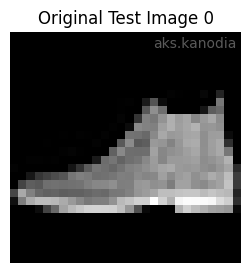

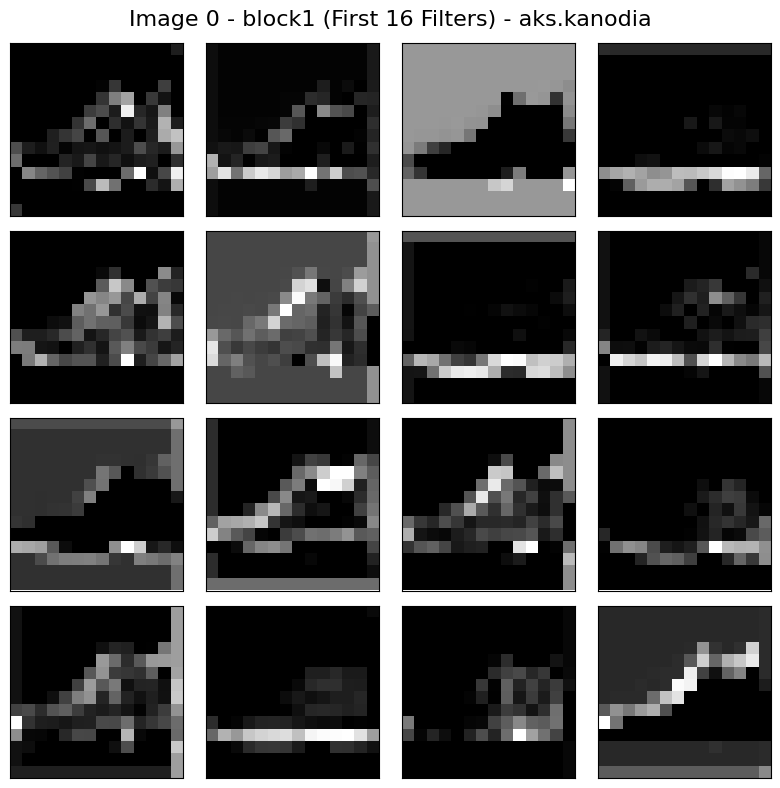

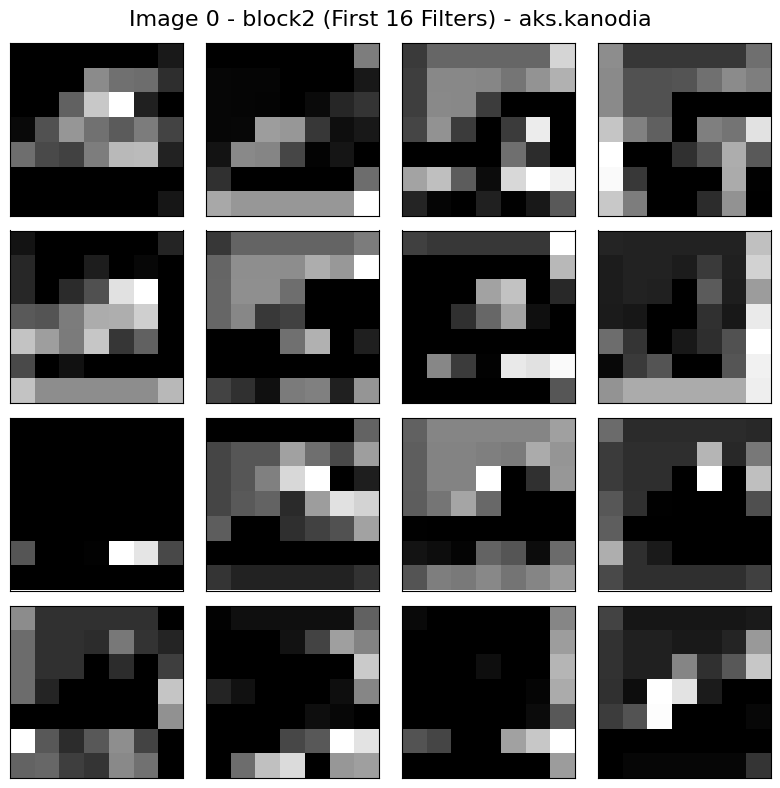

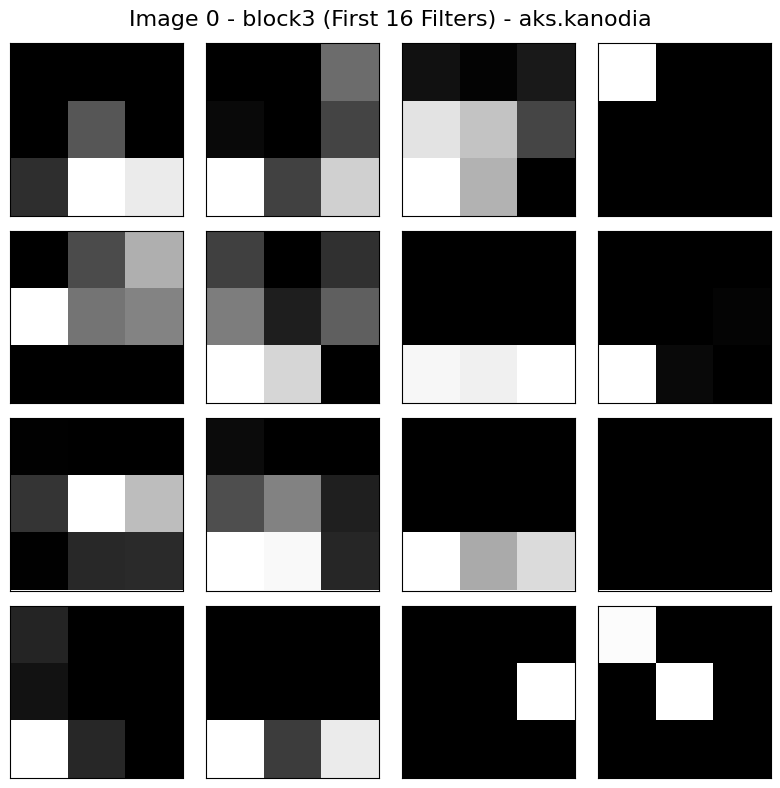


--- Visualizing Feature Maps for Test Image 1 ---


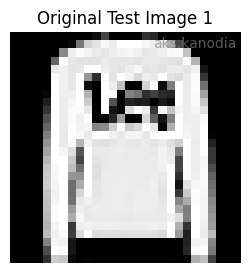

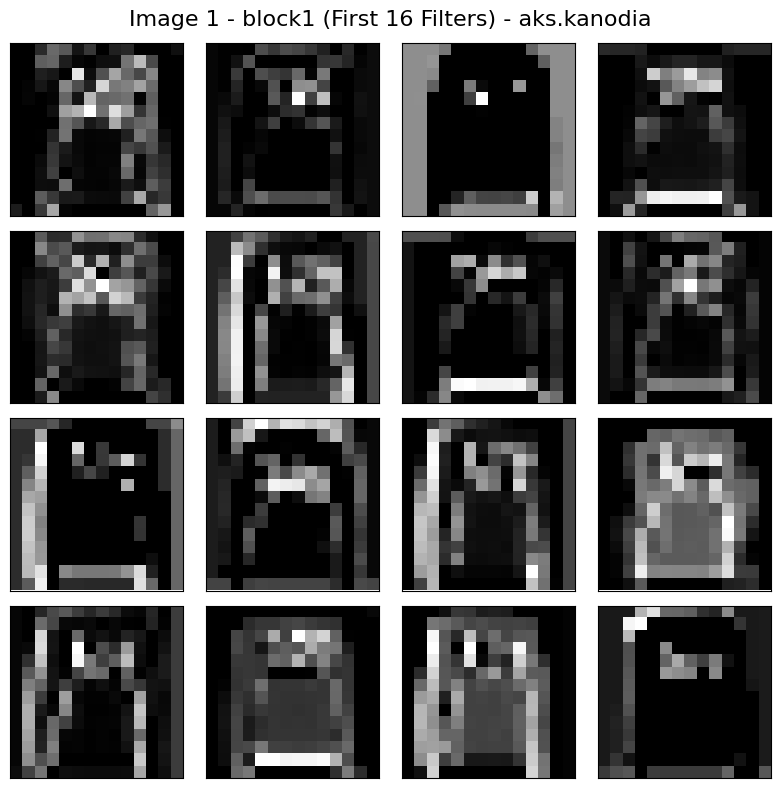

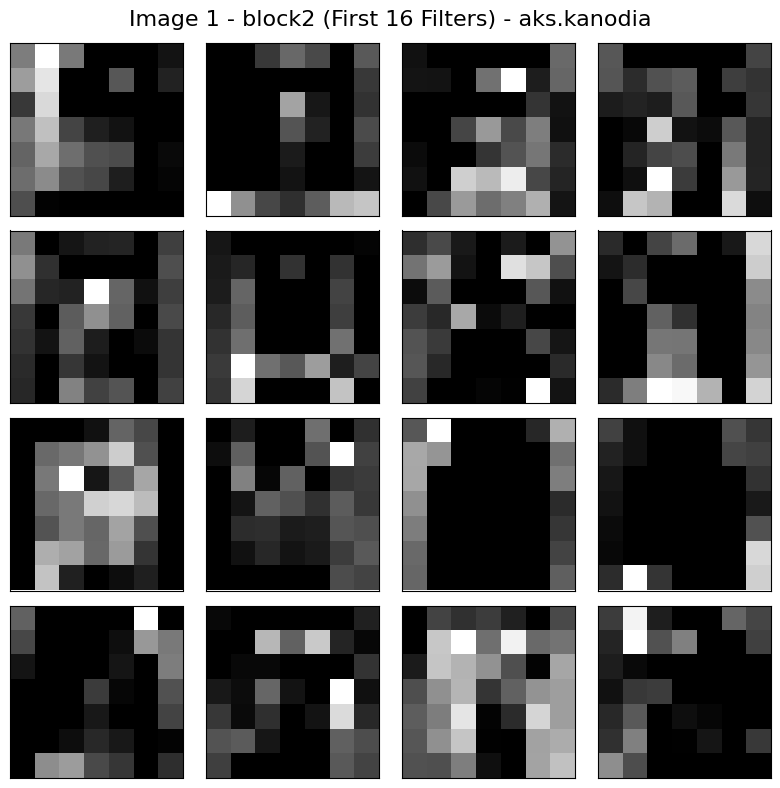

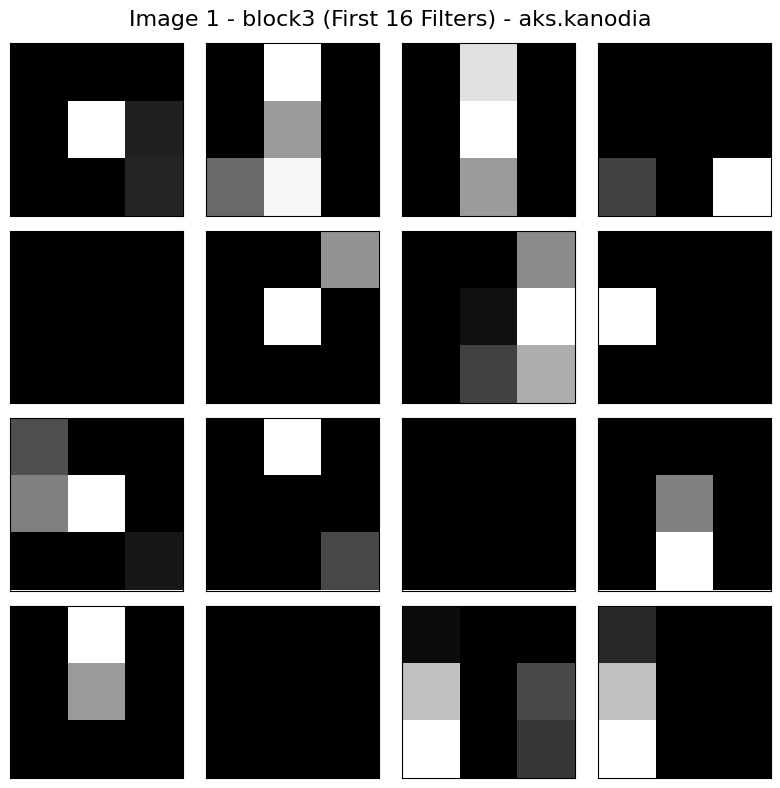


--- Visualizing Feature Maps for Test Image 2 ---


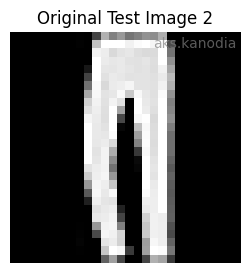

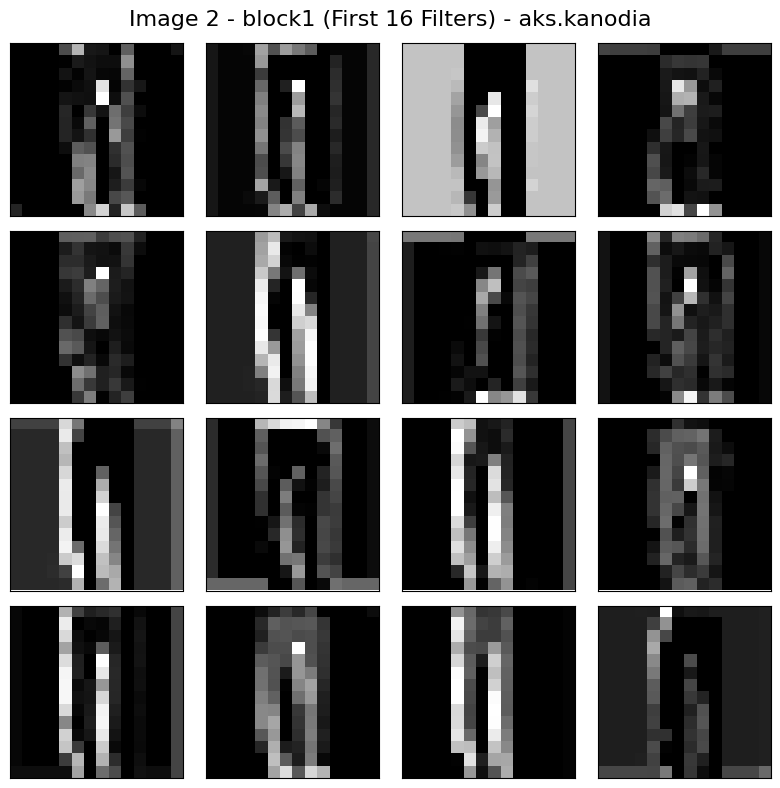

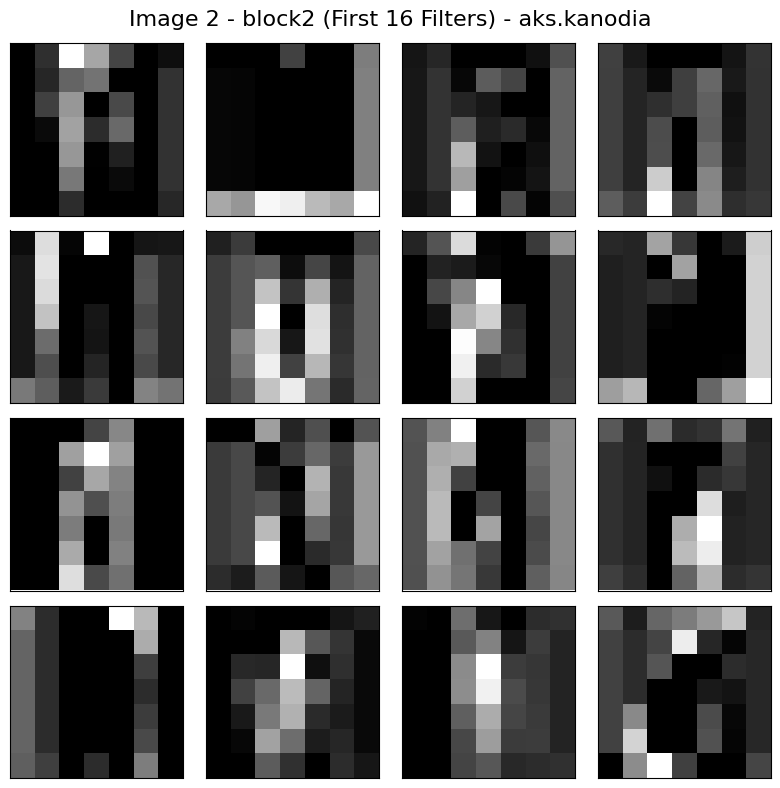

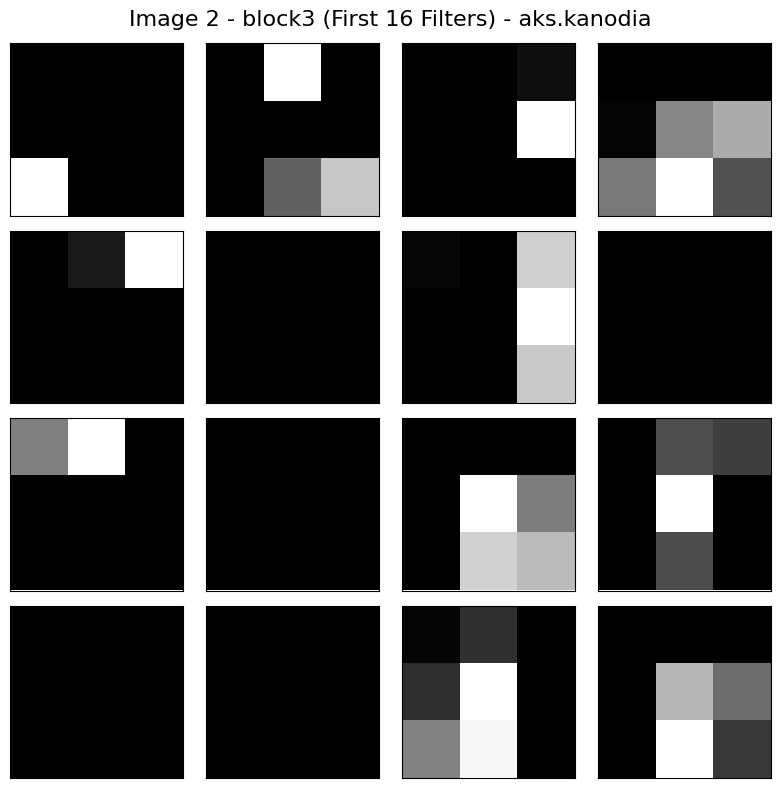

In [21]:
best_classifier_model = load_model_for_viz(CLASSIFIER_MODEL_PATH, MODEL_DROPOUT)

# Get feature maps
_, _, fmaps_classifier = best_classifier_model(images)

# Plot for the first 3 images
visualize_feature_maps(fmaps_classifier, images, image_indices=[0, 1, 2], save_path_prefix='fm_classifier')

# run again with viridis?

#### Best Regressor Model


--- Visualizing Feature Maps for Test Image 0 ---


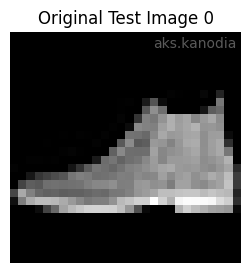

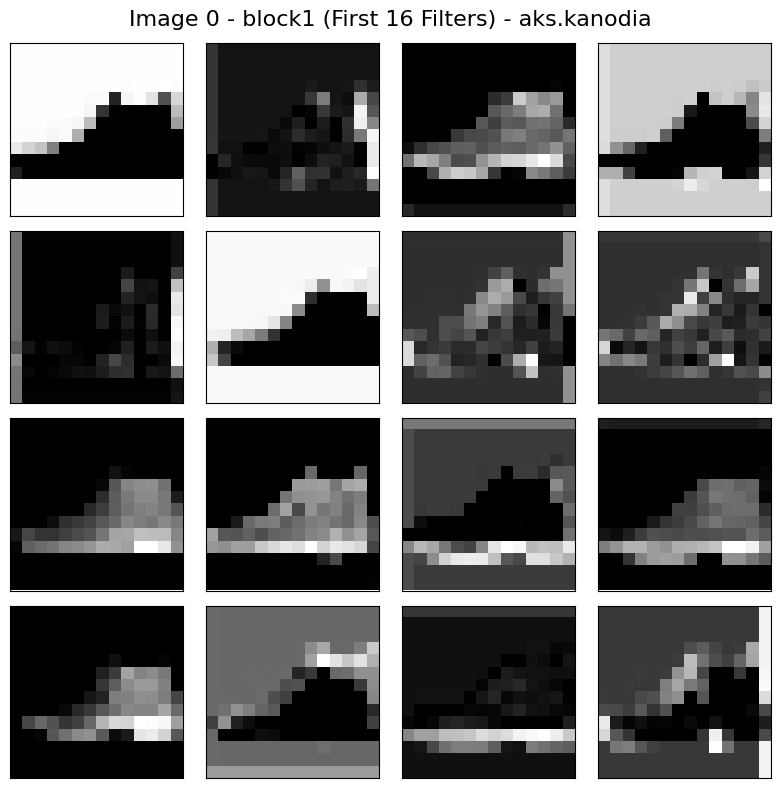

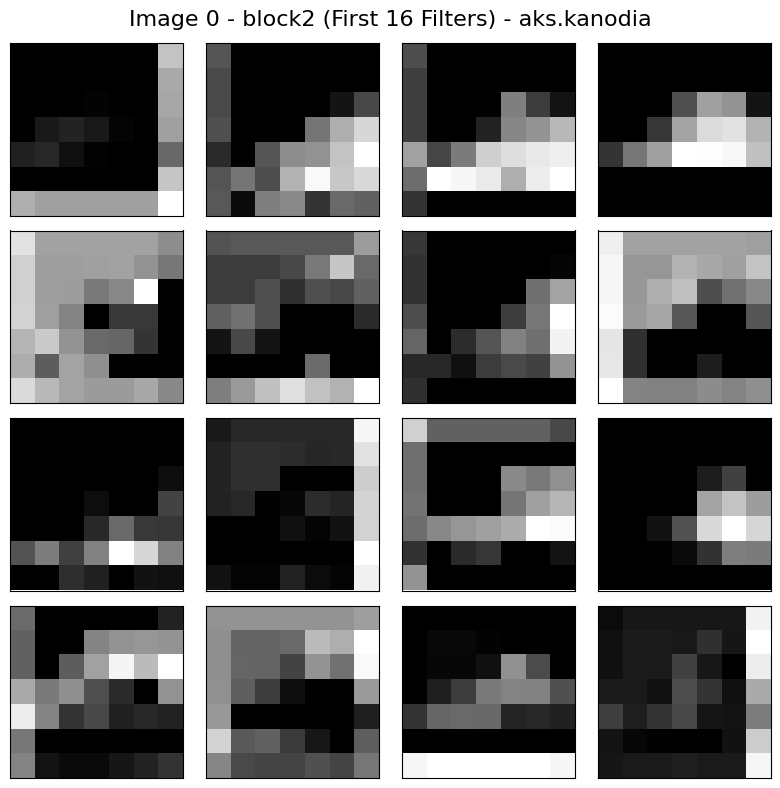

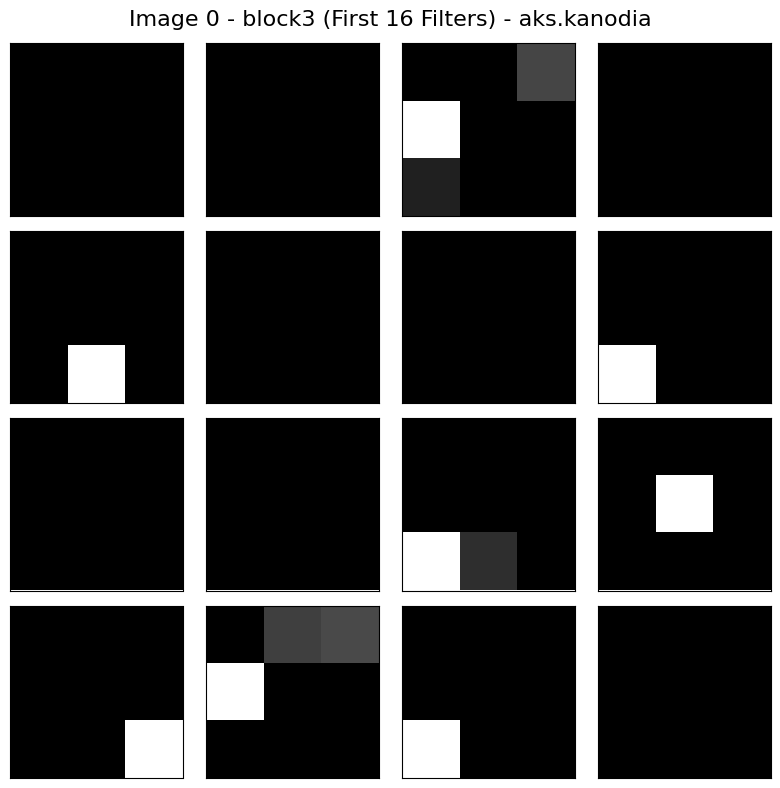


--- Visualizing Feature Maps for Test Image 1 ---


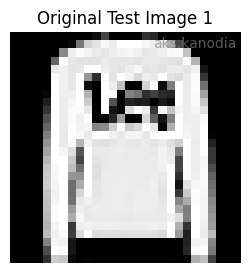

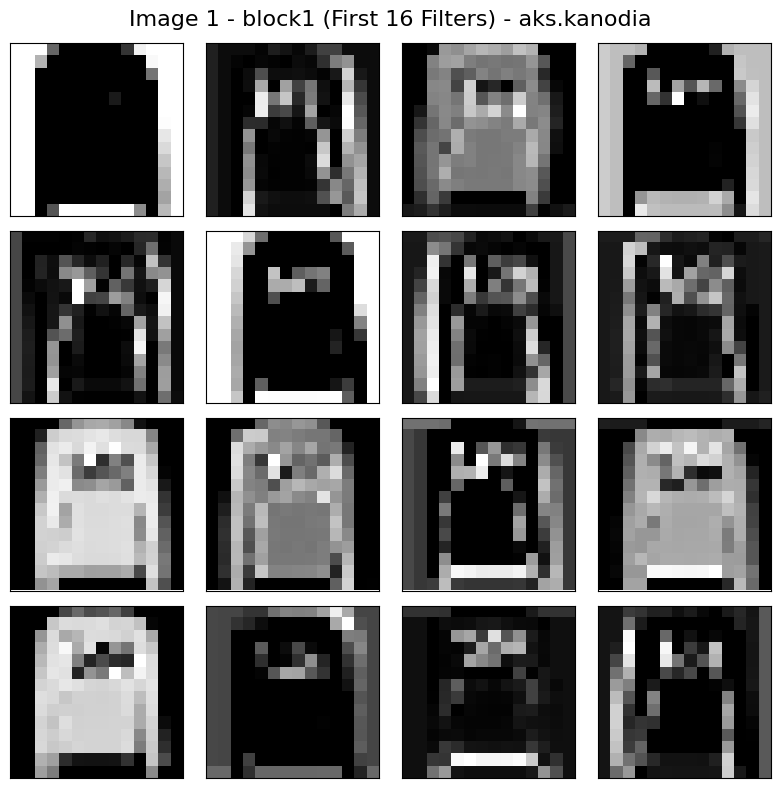

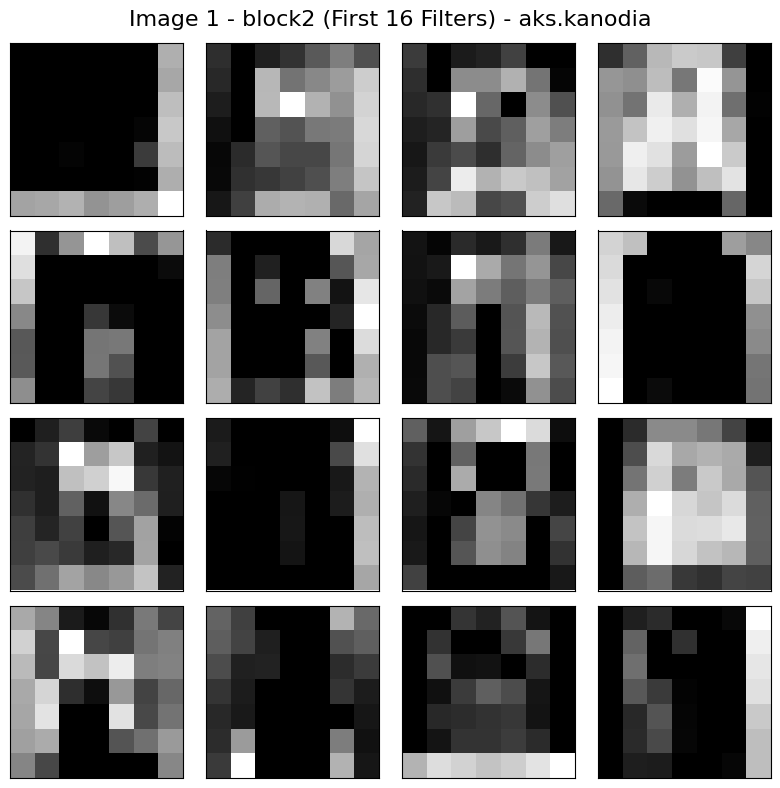

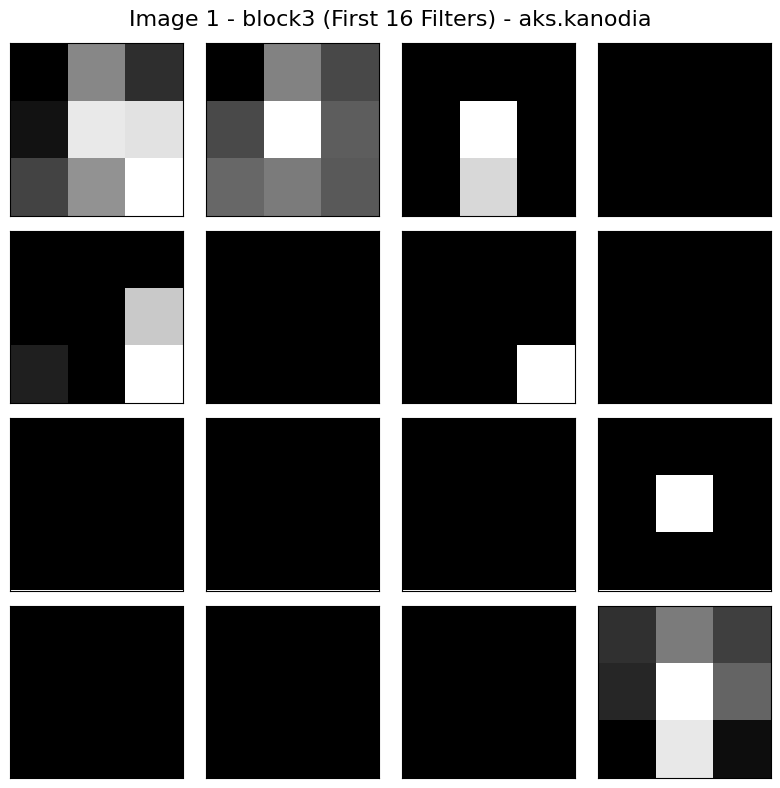


--- Visualizing Feature Maps for Test Image 2 ---


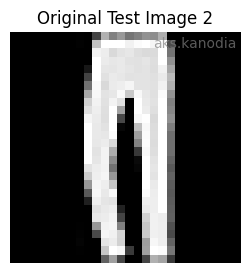

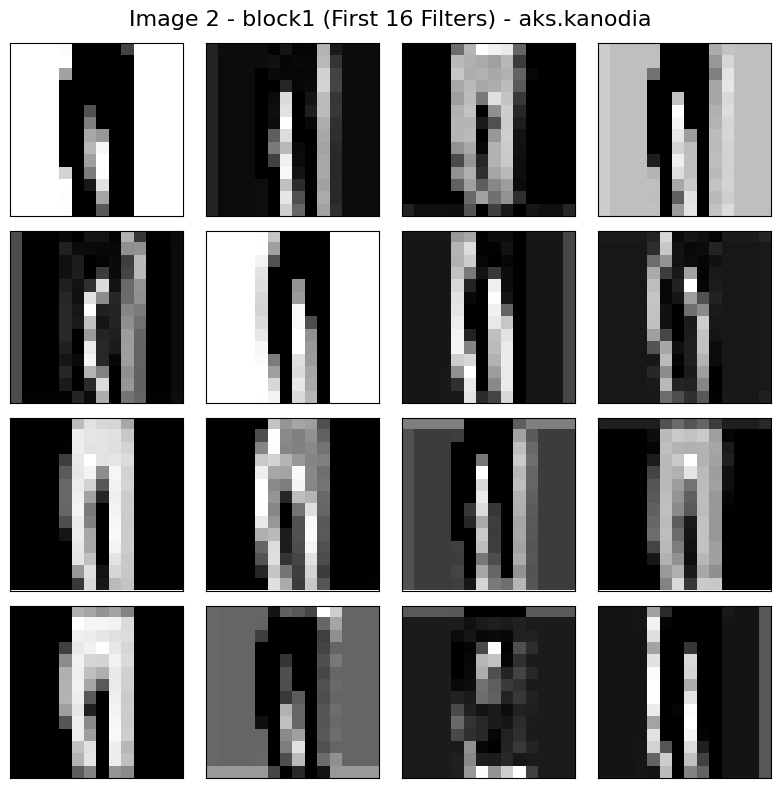

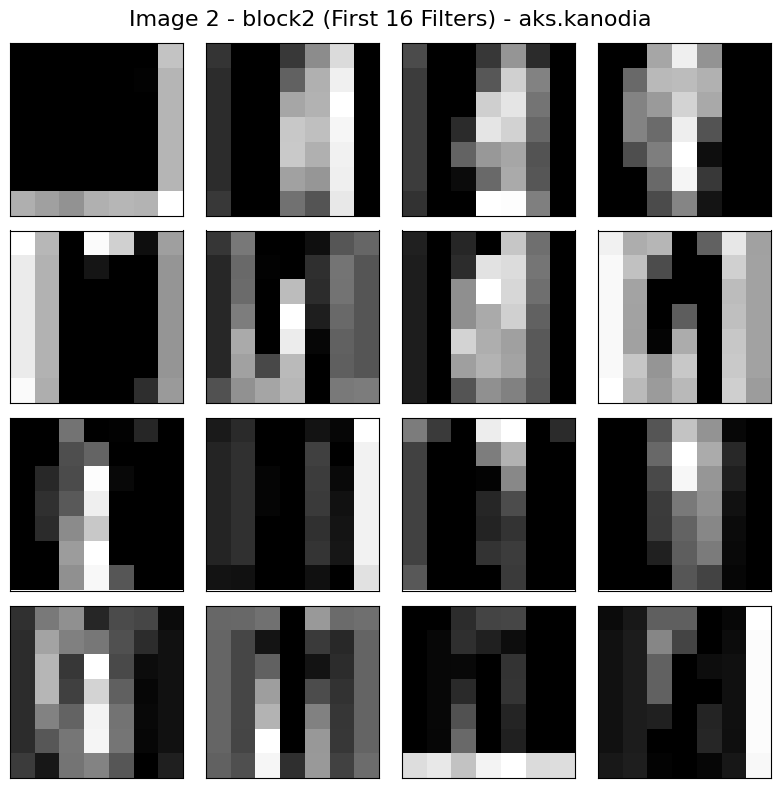

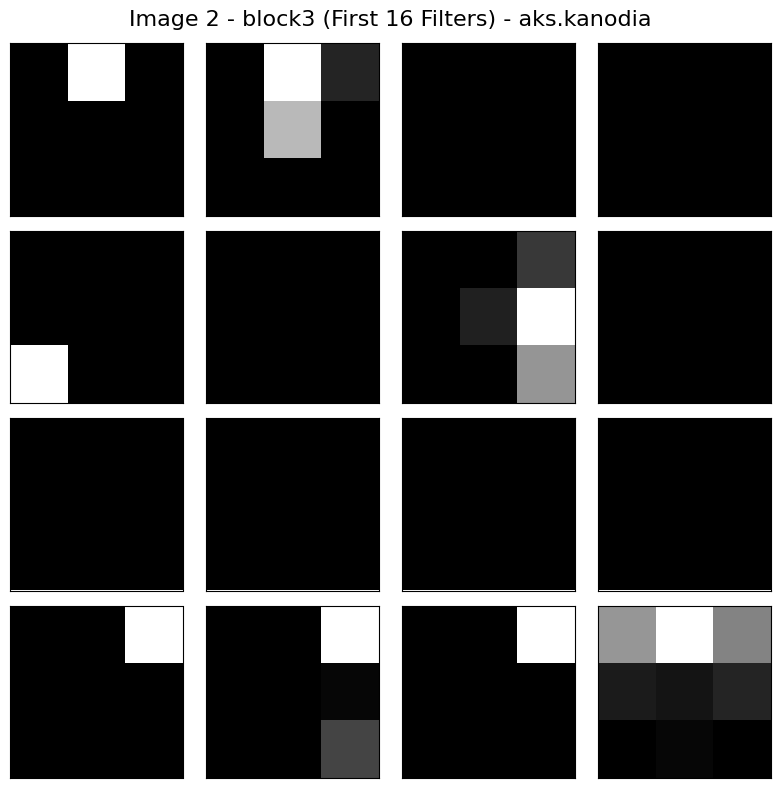

In [22]:
best_regressor_model = load_model_for_viz(REGRESSOR_MODEL_PATH, MODEL_DROPOUT)

# Get feature maps
_, _, fmaps_regressor = best_regressor_model(images)

# Plot for the same first 3 images
visualize_feature_maps(fmaps_regressor, images, image_indices=[0, 1, 2], save_path_prefix='fm_regressor')